# Task 1 - Urban vs Forest (Sentinel-2 + ANN)

**Description:** Use Sentinel 2 data to classify a patch as urban or forested area. This task is very similar to the one you did in Lab-3. You can see why, if possible, we prefer Bayesian classifiers. 

## Step 1 - Pose the task as a function

ANN approximates functions → write the task as $y = f(\mathbf{x})$:

- **Input $\mathbf{x}$:** $200\times200$ patch (B02–B08 or NDVI)
- **Output $y$:** $0$ = forest, $1$ = urban
- **Function $f$:** patch → class
- Training learns weights so $f_\theta(\mathbf{x})$ matches the true label
- Lab-3: one NDVI value + Bayes; here: whole patch + ANN

## Step 2 - Create training data (real Sentinel-2)

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import rasterio
from sklearn.model_selection import train_test_split

ROOT = Path.cwd()
DATA = ROOT / "scenes" if (ROOT / "scenes").exists() else ROOT.parent / "scenes"
BANDS = ["B02", "B03", "B04", "B08"]
PATCH, STRIDE = 200, 104
FOREST, URBAN = 0, 1


def load_stack(prefix: str) -> np.ndarray:
    bands = []
    for b in BANDS:
        with rasterio.open(DATA / f"{prefix}_{b}.tif") as src:
            bands.append(src.read(1).astype(np.float32))
    return np.stack(bands, axis=-1)


def extract_patches(img: np.ndarray, label: int):
    h, w, _ = img.shape
    xs, ys = [], []
    for r in range(0, h - PATCH + 1, STRIDE):
        for c in range(0, w - PATCH + 1, STRIDE):
            xs.append(img[r : r + PATCH, c : c + PATCH])
            ys.append(label)
    return xs, ys


forest = load_stack("s2_natural")
urban = load_stack("s2_urban")

X_list, y_list = [], []
for img, lab in [(forest, FOREST), (urban, URBAN)]:
    xs, ys = extract_patches(img, lab)
    X_list.extend(xs)
    y_list.extend(ys)

X = np.stack(X_list) 
y = np.asarray(y_list)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

print(f"forest tile: {forest.shape}, urban tile: {urban.shape}")
print(f"all patches X={X.shape}, y={y.shape}, counts={np.bincount(y)}  (0=forest, 1=urban)")
print(f"train: {X_train.shape}, {np.bincount(y_train)} | test: {X_test.shape}, {np.bincount(y_test)}")

forest tile: (512, 512, 4), urban tile: (512, 512, 4)
all patches X=(32, 200, 200, 4), y=(32,), counts=[16 16]  (0=forest, 1=urban)
train: (24, 200, 200, 4), [12 12] | test: (8, 200, 200, 4), [4 4]


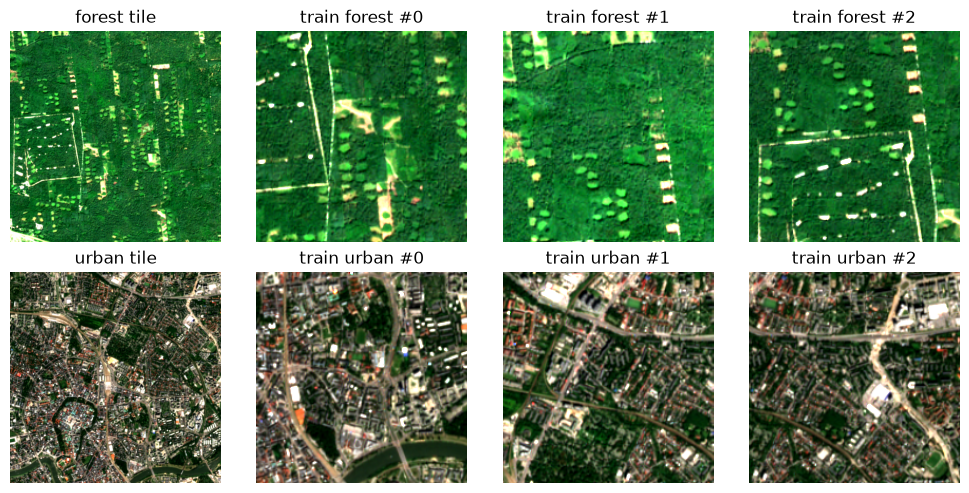

In [2]:
def rgb_preview(patch: np.ndarray) -> np.ndarray:
    rgb = patch[..., [2, 1, 0]].astype(np.float32)
    lo, hi = np.percentile(rgb, (2, 98))
    return np.clip((rgb - lo) / (hi - lo + 1e-6), 0, 1)


fig, ax = plt.subplots(2, 4, figsize=(10, 5))
for i, (title, img) in enumerate([("forest tile", forest), ("urban tile", urban)]):
    ax[i, 0].imshow(rgb_preview(img))
    ax[i, 0].set_title(title)
    ax[i, 0].axis("off")

for j in range(3):
    ax[0, j + 1].imshow(rgb_preview(X_train[y_train == FOREST][j]))
    ax[0, j + 1].set_title(f"train forest #{j}")
    ax[0, j + 1].axis("off")
    ax[1, j + 1].imshow(rgb_preview(X_train[y_train == URBAN][j]))
    ax[1, j + 1].set_title(f"train urban #{j}")
    ax[1, j + 1].axis("off")
plt.tight_layout()
plt.show()

## Step 3 - Barebone ANN architecture

In [3]:
import tensorflow as tf


def patch_features(patches: np.ndarray) -> np.ndarray:
    feats = patches.reshape(patches.shape[0], -1, patches.shape[-1]).mean(axis=1)
    return feats.astype(np.float32)


F_train = patch_features(X_train)
F_test = patch_features(X_test)
mu, sigma = F_train.mean(axis=0), F_train.std(axis=0) + 1e-6
F_train = (F_train - mu) / sigma
F_test = (F_test - mu) / sigma

y_train_f = y_train.astype(np.float32)
y_test_f = y_test.astype(np.float32)

model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(4,)),
    tf.keras.layers.Dense(8, activation="relu"),
    tf.keras.layers.Dense(1, activation="sigmoid"),
])
model.compile(
    loss="binary_crossentropy",
    optimizer=tf.keras.optimizers.Adam(0.01),
    metrics=["accuracy"],
)
model.summary()
print("F_train", F_train.shape, "F_test", F_test.shape)

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 8)              │            40 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 49 (196.00 B)

 Trainable params: 49 (196.00 B)

 Non-trainable params: 0 (0.00 B)

F_train (24, 4) F_test (8, 4)


## Step 4 - Train, score

A barebone Dense(8)+Adam(0.01): train_acc=1.000, test_acc=1.000, loss=0.0030


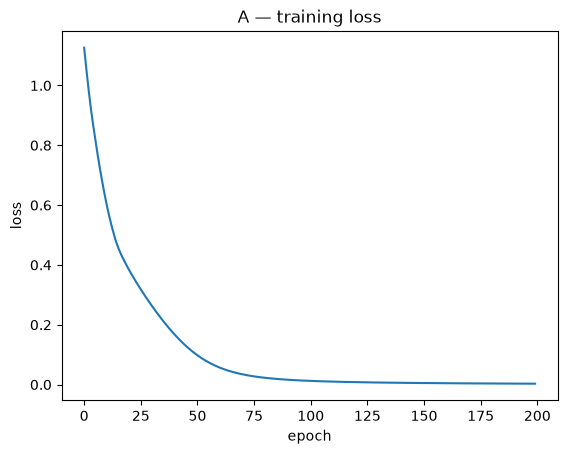

In [4]:
# --- A: barebone baseline ---
tf.keras.utils.set_random_seed(42)
model_A = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(4,)),
    tf.keras.layers.Dense(8, activation="relu"),
    tf.keras.layers.Dense(1, activation="sigmoid"),
])
model_A.compile(loss="binary_crossentropy", optimizer=tf.keras.optimizers.Adam(0.01), metrics=["accuracy"])
hist_A = model_A.fit(F_train, y_train_f, epochs=200, verbose=0)
tr = model_A.evaluate(F_train, y_train_f, verbose=0)
te = model_A.evaluate(F_test, y_test_f, verbose=0)
print(f"A barebone Dense(8)+Adam(0.01): train_acc={tr[1]:.3f}, test_acc={te[1]:.3f}, loss={hist_A.history['loss'][-1]:.4f}")

plt.plot(hist_A.history["loss"])
plt.xlabel("epoch"); plt.ylabel("loss"); plt.title("A — training loss")
plt.show()

In [5]:
def run_variant(name, layer_list, optimizer, epochs=200):
    tf.keras.utils.set_random_seed(42)
    m = tf.keras.Sequential([tf.keras.layers.Input(shape=(4,)), *layer_list])
    m.compile(loss="binary_crossentropy", optimizer=optimizer, metrics=["accuracy"])
    hist = m.fit(F_train, y_train_f, epochs=epochs, verbose=0)
    tr = m.evaluate(F_train, y_train_f, verbose=0)
    te = m.evaluate(F_test, y_test_f, verbose=0)
    row = {
        "name": name,
        "train_acc": float(tr[1]),
        "test_acc": float(te[1]),
        "final_loss": float(hist.history["loss"][-1]),
        "epochs": epochs,
    }
    print(
        f"{name}: train_acc={row['train_acc']:.3f}, "
        f"test_acc={row['test_acc']:.3f}, final_loss={row['final_loss']:.4f}"
    )
    return row, hist


rows = []

r, _ = run_variant(
    "A barebone Dense(8) Adam(0.01)",
    [tf.keras.layers.Dense(8, activation="relu"), tf.keras.layers.Dense(1, activation="sigmoid")],
    tf.keras.optimizers.Adam(0.01),
)
rows.append(r)

r, _ = run_variant(
    "B wider Dense(32) Adam(0.01)",
    [tf.keras.layers.Dense(32, activation="relu"), tf.keras.layers.Dense(1, activation="sigmoid")],
    tf.keras.optimizers.Adam(0.01),
)
rows.append(r)

r, _ = run_variant(
    "C deeper Dense(16)-Dense(8) Adam(0.01)",
    [
        tf.keras.layers.Dense(16, activation="relu"),
        tf.keras.layers.Dense(8, activation="relu"),
        tf.keras.layers.Dense(1, activation="sigmoid"),
    ],
    tf.keras.optimizers.Adam(0.01),
)
rows.append(r)

r, _ = run_variant(
    "D barebone Dense(8) SGD(0.05)",
    [tf.keras.layers.Dense(8, activation="relu"), tf.keras.layers.Dense(1, activation="sigmoid")],
    tf.keras.optimizers.SGD(0.05),
)
rows.append(r)

r, _ = run_variant(
    "E barebone Dense(8) Adam(0.001)",
    [tf.keras.layers.Dense(8, activation="relu"), tf.keras.layers.Dense(1, activation="sigmoid")],
    tf.keras.optimizers.Adam(0.001),
    epochs=500,
)
rows.append(r)

A barebone Dense(8) Adam(0.01): train_acc=1.000, test_acc=1.000, final_loss=0.0035
B wider Dense(32) Adam(0.01): train_acc=1.000, test_acc=1.000, final_loss=0.0003
C deeper Dense(16)-Dense(8) Adam(0.01): train_acc=1.000, test_acc=1.000, final_loss=0.0006
D barebone Dense(8) SGD(0.05): train_acc=1.000, test_acc=1.000, final_loss=0.0206
E barebone Dense(8) Adam(0.001): train_acc=1.000, test_acc=1.000, final_loss=0.0818


### Findings (from this run)

| ID | Setup | test_acc | final_loss |
|----|--------|----------|------------|
| A | Dense(8), Adam(0.01) | 1.000 | 0.0035 |
| B | Dense(32), Adam(0.01) | 1.000 | **0.0003** |
| C | Dense(16)→Dense(8), Adam(0.01) | 1.000 | 0.0006 |
| D | Dense(8), SGD(0.05) | 1.000 | 0.0206 |
| E | Dense(8), Adam(0.001), 500 ep | 1.000 | 0.0818 |

- All 5 runs: **train_acc = test_acc = 1.000** → classes are easy to separate with band-mean features
- Accuracy is saturated; only **loss** shows differences
- **Best loss:** B (wider) ≈ 0.0003, then C (deeper) ≈ 0.0006
- **Adam >> SGD** here: A loss 0.0035 vs D 0.0206 on the same Dense(8)
- **Small LR is slower:** E (Adam 0.001) still correct, but highest loss (0.0818) even after more epochs
- Barebone A is already enough for this task - extra width/depth only polishes confidence/loss
- Why Lab-3 liked Bayes: same easy split, but with an **interpretable rule** (e.g. NDVI threshold) and **per-pixel** maps, no architecture search
- Caveat: only **8 test patches** → perfect accuracy ≠ hard generalization